In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [39]:
iris = load_iris()
X = iris.data
y = iris.target

In [40]:
n = 10
def lr_iris(target_class):
    accuracies = []

    y_binary = np.where(y == target_class, 0, 1)
 
    for i in range(n):
        X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.3, random_state=i)
 
        model = LogisticRegression(max_iter=1000)
        model.fit(X_train, y_train)
 
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        accuracies.append(acc)

    mean_acc = np.mean(accuracies)
    return mean_acc

In [41]:
acc_setosa = lr_iris(target_class=0)
acc_versicolor = lr_iris(target_class=1)
acc_virginica = lr_iris(target_class=2)

print(f"setosa {acc_setosa:.4f}")
print(f"versicolor {acc_versicolor:.4f}")
print(f"virginica {acc_virginica:.4f}")

setosa 1.0000
versicolor 0.6911
virginica 0.9644


In [89]:
wine = pd.read_csv("wine.txt")
 
X = wine.drop(columns=["class"]).values
y = wine["class"].values
 
n = 100
train_size = 0.7
 
acc_plain = []
acc_scaled = []
 
for _ in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size)

    clf = DecisionTreeClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc_plain.append(np.mean(y_pred == y_test))
 
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
 
    clf_s = DecisionTreeClassifier()
    clf_s.fit(X_train_s, y_train)
    y_pred_s = clf_s.predict(X_test_s)
    acc_scaled.append(np.mean(y_pred_s == y_test))
 
acc_no_scaling = acc_plain
acc_scaling = acc_scaled
 
mean_plain = np.mean(acc_plain)
mean_scaled = np.mean(acc_scaled)

Średnia skuteczność bez skalowania: 0.9087
Średnia skuteczność ze skalowaniem: 0.9106


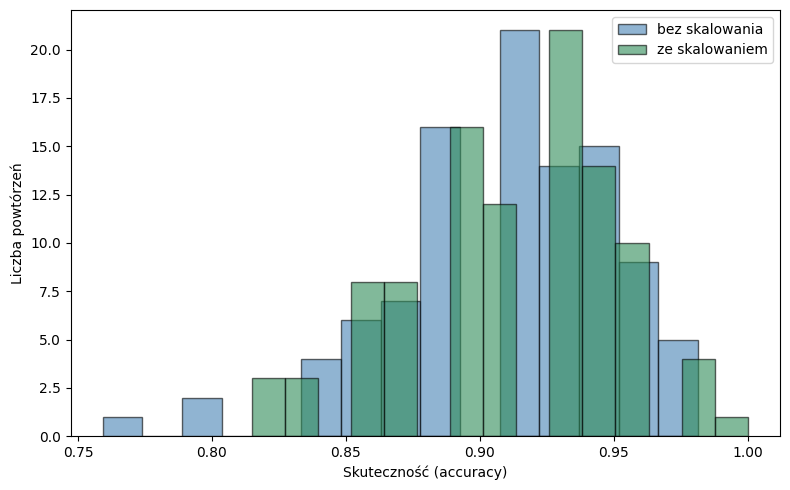

In [93]:
print(f"Średnia skuteczność bez skalowania: {mean_plain:.4f}")
print(f"Średnia skuteczność ze skalowaniem: {mean_scaled:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(acc_no_scaling, bins=15, alpha=0.6, color="steelblue", edgecolor="black", label="bez skalowania")
plt.hist(acc_scaling, bins=15, alpha=0.6, color="seagreen",edgecolor="black", label="ze skalowaniem")
plt.xlabel("Skuteczność (accuracy)")
plt.ylabel("Liczba powtórzeń")
plt.legend()
plt.tight_layout()

In [ ]:
titanic = pd.read_csv("titanic.csv")
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"
 
data = titanic[features + [target]].copy()
 
n = 100
accuracies = []
 
for i in range(n):
    train_df, test_df = train_test_split(data, test_size=0.3, random_state=i)
 
    train_df = train_df.copy()
    test_df = test_df.copy()
    
    age_median = train_df["Age"].median()
    train_df["Age"] = train_df["Age"].fillna(age_median)
    test_df["Age"] = test_df["Age"].fillna(age_median)
 
    embarked_mode = train_df["Embarked"].mode()[0]
    train_df["Embarked"] = train_df["Embarked"].fillna(embarked_mode)
    test_df["Embarked"] = test_df["Embarked"].fillna(embarked_mode)

    train_encoded = pd.get_dummies(train_df, columns=["Sex", "Embarked"])
    test_encoded = pd.get_dummies(test_df, columns=["Sex", "Embarked"])

    X_train = train_encoded.drop(columns=[target])
    y_train = train_encoded[target]
    X_test = test_encoded.drop(columns=[target])
    y_test = test_encoded[target]
 
    model = RandomForestClassifier(n_estimators=200, random_state=i)
    model.fit(X_train, y_train)
 
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
 
print(f"Średnia skuteczność (accuracy): {np.mean(accuracies)*100:.1f}%")

Średnia skuteczność (accuracy): 80.3%
